# CNN-Based Image Classification

**Course:** Computer Vision & Pattern Recognition (CVPR) - Mid Assignment
**Student ID:** 23-50691-1

## 1. Introduction

The objective of this assignment is to develop a
Convolutional Neural Network (CNN) model for image
classification.

In this project, we use the **Fashion-MNIST** dataset
to classify clothing images into ten different categories.

In [ ]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Fix the random seed so that results can be reproduced
torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

cuda


## 2. Dataset Loading and Exploration

In this section, we load the Fashion-MNIST dataset.
The dataset is open access (Zalando Research) and is also
available on Kaggle and Hugging Face. Here it is downloaded
automatically through `torchvision.datasets`.

We explore the dataset and check the number
of images available in each category.

In [ ]:
import os

dataset_path = './data'

# Download (first run only) and load the original train / test splits
raw_train = datasets.FashionMNIST(dataset_path, train=True,  download=True)
raw_test  = datasets.FashionMNIST(dataset_path, train=False, download=True)

class_names = raw_train.classes

print("Dataset Path:", os.path.abspath(dataset_path))
print("Classes:", class_names)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]

Dataset Path: /content/data
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 3. Dataset Description

| Property | Value |
|---|---|
| Name | Fashion-MNIST |
| Source | Zalando Research (open access; Kaggle / Hugging Face / torchvision) |
| Task | Multi-class image classification |
| Image size | 28 x 28 pixels, **grayscale** (1 channel) |
| Training images | 60,000 |
| Test images | 10,000 |
| Number of classes | 10 |

The dataset contains ten different clothing categories:

1. T-shirt/top
2. Trouser
3. Pullover
4. Dress
5. Coat
6. Sandal
7. Shirt
8. Sneaker
9. Bag
10. Ankle boot

The classes are perfectly balanced (6,000 training images per class),
so accuracy is a fair metric for this dataset.

In [ ]:
# Number of images in each class (training split)
train_targets = np.array(raw_train.targets)

for idx, class_name in enumerate(class_names):

    print(class_name, ":", (train_targets == idx).sum())

T-shirt/top : 6000
Trouser : 6000
Pullover : 6000
Dress : 6000
Coat : 6000
Sandal : 6000
Shirt : 6000
Sneaker : 6000
Bag : 6000
Ankle boot : 6000


/tmp/ipykernel_393/904523299.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  train_targets = np.array(raw_train.targets)


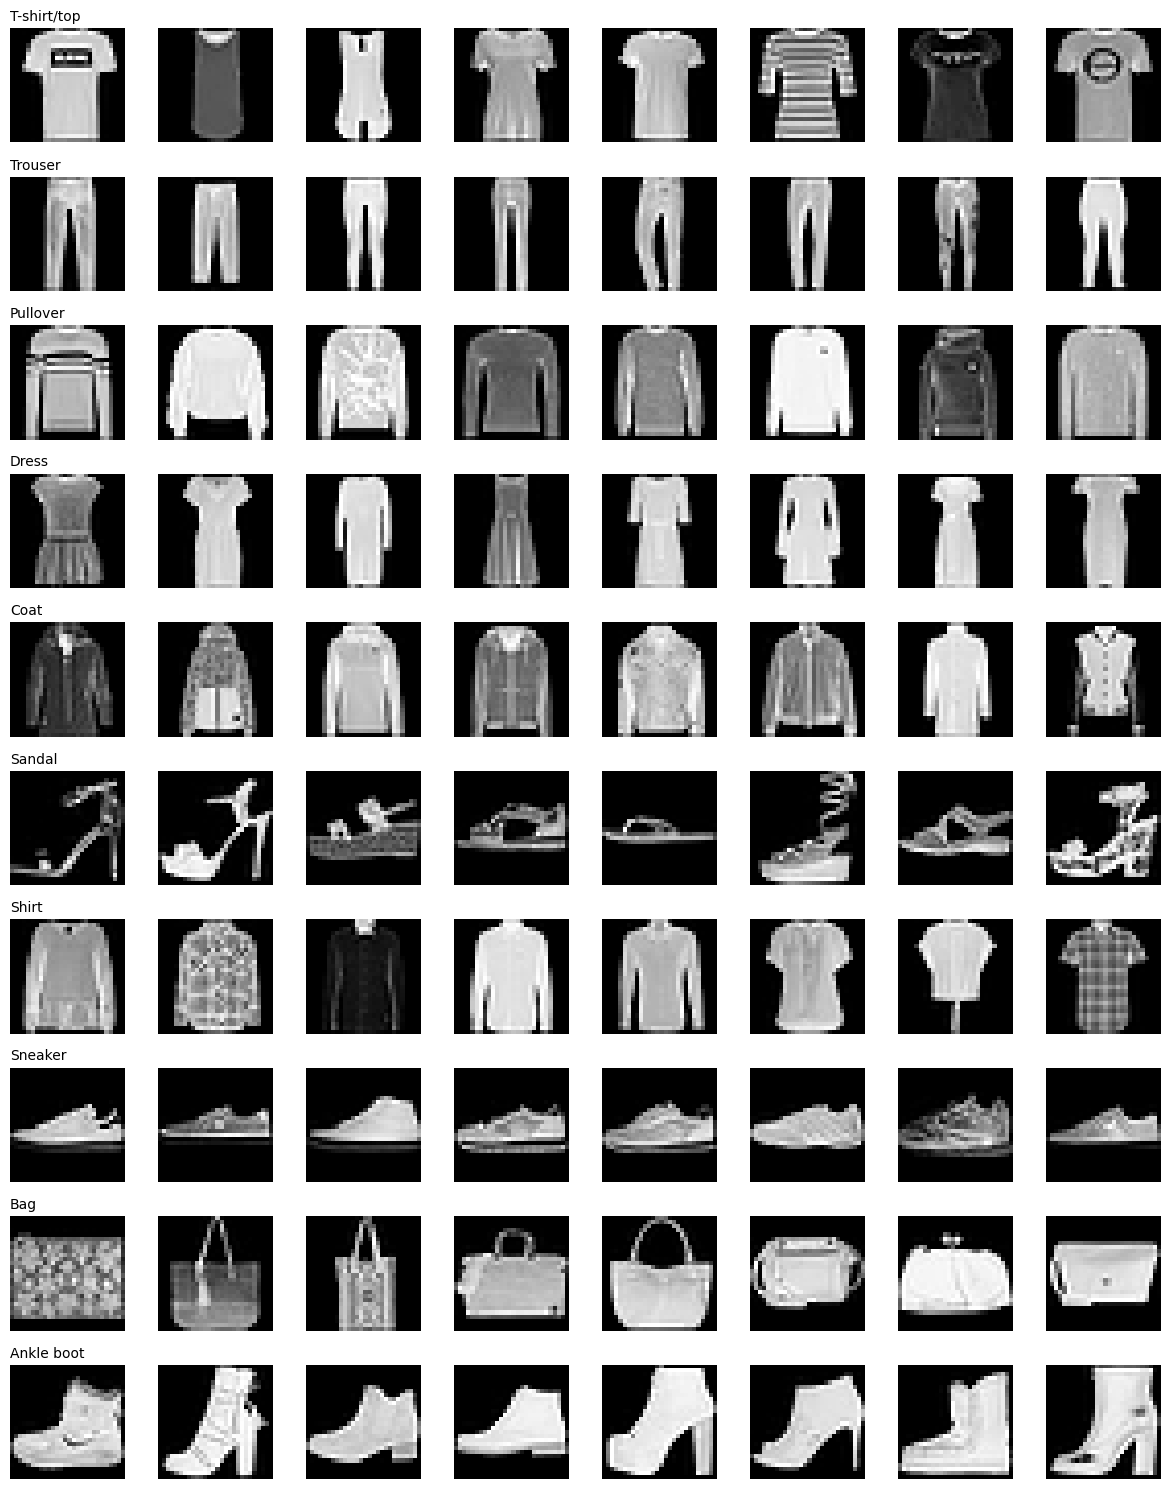

In [ ]:
# Show some sample images from each class
fig, axes = plt.subplots(len(class_names), 8, figsize=(12, 15))

for cls in range(len(class_names)):

    idxs = np.where(train_targets == cls)[0][:8]

    for j, idx in enumerate(idxs):

        axes[cls, j].imshow(raw_train[idx][0], cmap='gray')
        axes[cls, j].axis('off')

        if j == 0:
            axes[cls, j].set_title(class_names[cls], fontsize=10, loc='left')

plt.tight_layout()
plt.show()

## 4. Data Preprocessing

In this section, image transformations are applied
before training the CNN model.

- `RandomHorizontalFlip()` and `RandomRotation(10)` are used for data
  augmentation (training data only).
- `ToTensor()` converts images into PyTorch tensors with values in 0-1.
- `Normalize()` centres the pixel values using the dataset mean and
  standard deviation, which makes training faster and more stable.

The original 60,000 training images are split into
**80% training / 20% validation**. The official 10,000 test images are kept
unseen until the final evaluation.

In [ ]:
from torch.utils.data import random_split, Subset

# Mean and standard deviation of Fashion-MNIST training images
MEAN, STD = 0.2860, 0.3530

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,))
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,))
])

# Two copies of the same training data: one with augmentation, one without
full_train_data = datasets.FashionMNIST(
    dataset_path, train=True, download=True,
    transform=train_transform
)

full_val_data = datasets.FashionMNIST(
    dataset_path, train=True, download=True,
    transform=val_transform
)

train_size = int(0.8 * len(full_train_data))
val_size = len(full_train_data) - train_size

train_subset, val_subset = random_split(
    range(len(full_train_data)),
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_data = Subset(full_train_data, train_subset.indices)
val_data = Subset(full_val_data, val_subset.indices)

test_data = datasets.FashionMNIST(
    dataset_path, train=False, download=True,
    transform=val_transform
)

print("Dataset Loading Successful!")

Dataset Loading Successful!


## 5. Dataset Summary

In this section, we check the total number
of training, validation, and test images.

We also check the class names and their
corresponding numerical indices.

In [ ]:
print('Dataset Summary')

print('Train Data: ', len(train_data))

print('Validation Data: ', len(val_data))

print('Test Data: ', len(test_data))

print('Classes and Indices: ', full_train_data.class_to_idx)

Dataset Summary
Train Data:  48000
Validation Data:  12000
Test Data:  10000
Classes and Indices:  {'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}


## 6. Hyperparameter Settings

The following hyperparameters are used
for training the CNN model:

| Hyperparameter | Value | Rationale |
|---|---|---|
| Batch Size | 64 | Good balance between training speed and gradient noise |
| Learning Rate | 0.001 | Standard starting value for Adam |
| Number of Epochs | 10 | Enough for the curves to flatten on this dataset |
| Optimizer | Adam | Adaptive learning rate, converges quickly with little tuning |
| Loss Function | CrossEntropyLoss | Standard loss for multi-class classification |
| Dropout | 0.3 | Reduces over-fitting in the fully connected layer |

These values are used to train the model
and update its weights.

In [ ]:
batch_size = 64

learning_rate = 1e-3

epoch_number = 10

## 7. DataLoader Creation

DataLoader is used to load images in batches.

The batch size is set to 64. It helps the model
process images in small groups during training,
validation, and testing.

In [ ]:
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

In [ ]:
print("Training Batches:", len(trn_dl))

print("Validation Batches:", len(val_dl))

print("Testing Batches:", len(test_dl))

Training Batches: 750
Validation Batches: 188
Testing Batches: 157


In [ ]:
images, labels = next(iter(trn_dl))

print("Image Shape:", images.shape)

print("Label Shape:", labels.shape)

print("Labels:", labels)

Image Shape: torch.Size([64, 1, 28, 28])
Label Shape: torch.Size([64])
Labels: tensor([9, 8, 2, 6, 9, 0, 3, 5, 2, 1, 8, 2, 2, 0, 9, 2, 5, 3, 9, 8, 4, 0, 5, 6,
        8, 2, 5, 8, 9, 9, 4, 3, 7, 4, 0, 9, 9, 8, 8, 0, 1, 2, 5, 7, 6, 2, 4, 4,
        6, 5, 9, 9, 0, 8, 7, 6, 0, 9, 3, 4, 8, 5, 8, 7])


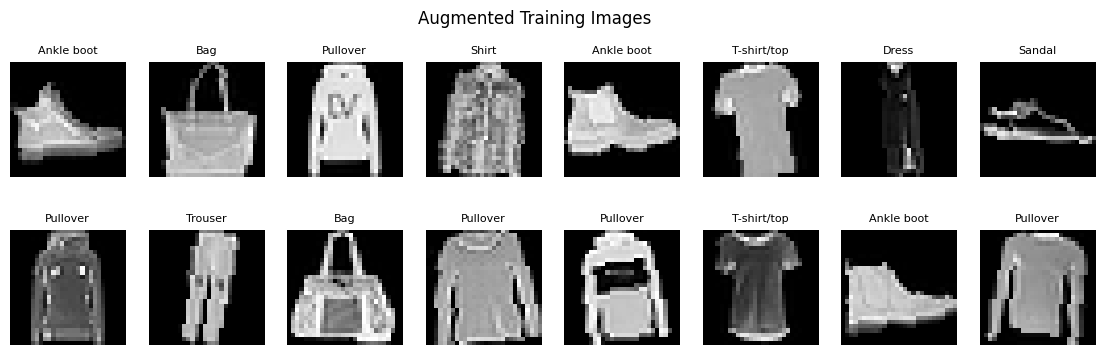

In [ ]:
# Visualise one augmented training batch (undo the normalisation for display)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i, ax in enumerate(axes.flat):

    ax.imshow(images[i][0] * STD + MEAN, cmap='gray')
    ax.set_title(class_names[labels[i]], fontsize=8)
    ax.axis('off')

plt.suptitle('Augmented Training Images')
plt.show()

## 8. CNN Model Architecture

A Convolutional Neural Network (CNN) is created
for image classification.

The model contains:

- Two Convolutional Layers (64 and 128 filters, 3 x 3 kernels)
- ReLU Activation Functions
- Two Max Pooling Layers
- One Flatten Layer
- Two Fully Connected Layers with one Dropout layer

**Design justification**

- The first convolution layer learns simple patterns such as edges and
  textures; the second combines them into larger shapes such as sleeves,
  straps and soles.
- 3 x 3 kernels are small and efficient, and stacking two of them gives a larger
  receptive field.
- Max pooling halves the image size (28 -> 13 -> 5), reducing computation and
  giving some tolerance to small shifts.
- Dropout (0.3) lowers the risk of over-fitting in the large fully connected layer.
- The input has **1 channel** (grayscale) and the final output layer contains
  ten neurons for ten clothing categories. The outputs are raw logits because
  `CrossEntropyLoss` applies softmax internally.

In [ ]:
from torch.optim import SGD, Adam

def get_model():

    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(1, 64, kernel_size=3),     # 28x28 -> 26x26
        nn.ReLU(),
        nn.MaxPool2d(2),                     # 26x26 -> 13x13

        nn.Conv2d(64, 128, kernel_size=3),   # 13x13 -> 11x11
        nn.ReLU(),
        nn.MaxPool2d(2),                     # 11x11 -> 5x5

        # Classifier
        nn.Flatten(),
        nn.Linear(128*5*5, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 10)

    ).to(device)

    loss_fn = nn.CrossEntropyLoss()

    optimizer = Adam(model.parameters(), lr=learning_rate)

    return model, loss_fn, optimizer

In [ ]:
!pip install torchsummary

## 9. Model Summary

The model summary shows the architecture
of the CNN model.

It displays the output shape and number
of parameters in each layer.

The model has approximately 0.9 million
trainable parameters (896,522).

In [ ]:
from torchsummary import summary

model, loss_fn, optimizer = get_model()

summary(model, input_size=(1, 28, 28))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 26, 26]             640
              ReLU-2           [-1, 64, 26, 26]               0
         MaxPool2d-3           [-1, 64, 13, 13]               0
            Conv2d-4          [-1, 128, 11, 11]          73,856
              ReLU-5          [-1, 128, 11, 11]               0
         MaxPool2d-6            [-1, 128, 5, 5]               0
           Flatten-7                 [-1, 3200]               0
            Linear-8                  [-1, 256]         819,456
              ReLU-9                  [-1, 256]               0
          Dropout-10                  [-1, 256]               0
           Linear-11                   [-1, 10]           2,570
Total params: 896,522
Trainable params: 896,522
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

## 10. Training and Validation Functions

In this section, two functions are created.

The training function trains the model
using training images.

The validation function checks the model
performance using validation images.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):

    model.train()

    epoch_losses, epoch_accuracies = [], []

    for x, y in data_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        prediction = model(x)

        batch_loss = loss_fn(prediction, y)

        batch_loss.backward()

        optimizer.step()

        epoch_losses.append(batch_loss.item())

        is_correct = (prediction.argmax(-1) == y).tolist()

        epoch_accuracies.extend(is_correct)

    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):

    model.eval()

    val_losses, val_accuracies = [], []

    for x, y in data_loader:

        x, y = x.to(device), y.to(device)

        prediction = model(x)

        val_losses.append(loss_fn(prediction, y).item())

        is_correct = (prediction.argmax(-1) == y).tolist()

        val_accuracies.extend(is_correct)

    return np.mean(val_losses), np.mean(val_accuracies)

## 11. Model Training

The CNN model is trained for 10 epochs.

During each epoch, training loss,
training accuracy, validation loss,
and validation accuracy are calculated.

These values help to monitor the model
learning performance.

In [ ]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):

    epoch_loss, epoch_accuracy = train_one_epoch(
        trn_dl, model, loss_fn, optimizer
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(
        val_dl, model, loss_fn
    )

    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f}"
        f" | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f}"
        f" | Val Accuracy: {v_acc*100:.2f}%"
    )

Epoch [1/10] | Train Loss: 0.5398 | Train Accuracy: 80.22% | Val Loss: 0.3916 | Val Accuracy: 85.41%
Epoch [2/10] | Train Loss: 0.3726 | Train Accuracy: 86.30% | Val Loss: 0.3313 | Val Accuracy: 87.62%
Epoch [3/10] | Train Loss: 0.3248 | Train Accuracy: 88.09% | Val Loss: 0.3079 | Val Accuracy: 88.88%
Epoch [4/10] | Train Loss: 0.2979 | Train Accuracy: 88.89% | Val Loss: 0.2756 | Val Accuracy: 90.22%
Epoch [5/10] | Train Loss: 0.2785 | Train Accuracy: 89.81% | Val Loss: 0.2622 | Val Accuracy: 90.43%
Epoch [6/10] | Train Loss: 0.2662 | Train Accuracy: 90.34% | Val Loss: 0.2640 | Val Accuracy: 90.32%
Epoch [7/10] | Train Loss: 0.2518 | Train Accuracy: 90.61% | Val Loss: 0.2567 | Val Accuracy: 90.62%
Epoch [8/10] | Train Loss: 0.2462 | Train Accuracy: 90.83% | Val Loss: 0.2544 | Val Accuracy: 91.02%
Epoch [9/10] | Train Loss: 0.2311 | Train Accuracy: 91.38% | Val Loss: 0.2369 | Val Accuracy: 91.67%
Epoch [10/10] | Train Loss: 0.2247 | Train Accuracy: 91.67% | Val Loss: 0.2464 | Val Accura

## 12. Training and Validation Loss

This graph shows the training loss
and validation loss over 10 epochs.

A decreasing loss indicates that
the model is learning from the data.

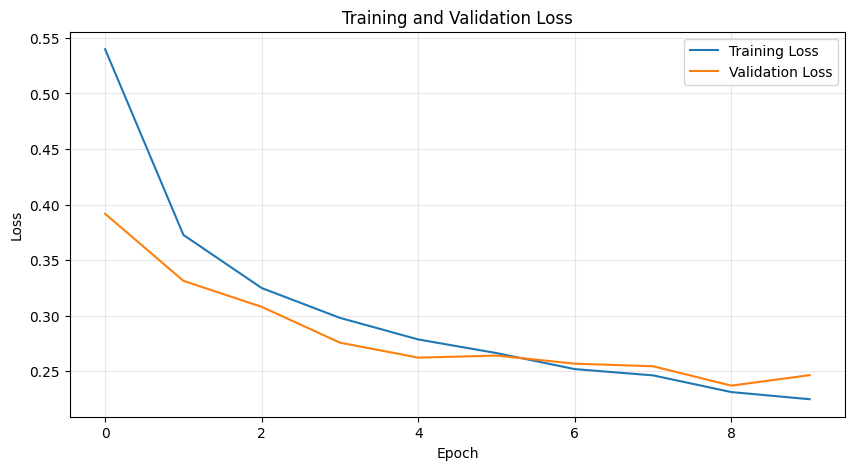

In [ ]:
# Plot Training and Validation Loss

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title('Training and Validation Loss')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Training and Validation Accuracy

This graph shows the training accuracy
and validation accuracy over 10 epochs.

It helps us understand how well
the model learns from the dataset.

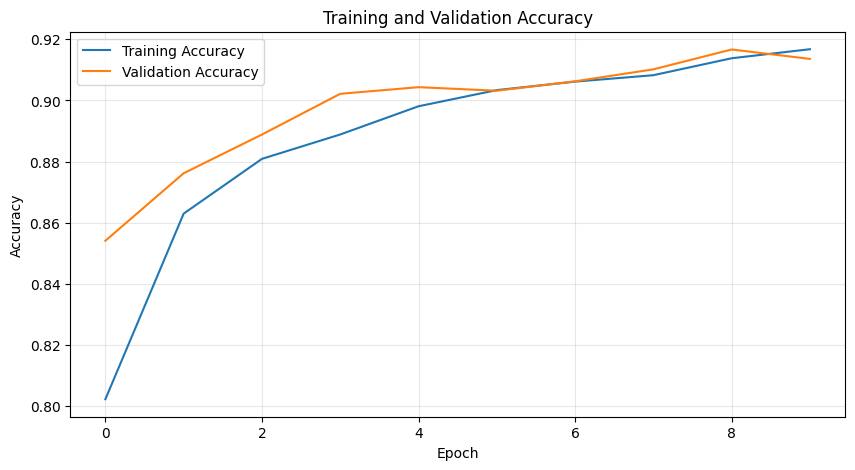

In [ ]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title('Training and Validation Accuracy')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Explanation of the Curves

- Both losses fall quickly in the first epochs and then flatten, which shows the model is converging.
- Accuracy rises in the same way. If the training curve keeps improving while the validation curve flattens,
  the model starts to over-fit; a small gap means it generalises well.
- Training accuracy can be slightly lower than validation accuracy early on because augmentation and dropout
  are active only during training.

*(Add your own observation here after running: the epoch where validation loss stopped improving and the final gap.)*

## 14. Model Evaluation on Test Dataset

The trained CNN model is evaluated
using the separate test dataset.

Test loss and test accuracy are calculated
to measure the model performance on unseen images.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

test_loss = 0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_dl:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = 100 * correct / total

print("Test Loss:", test_loss / len(test_dl))
print("Test Accuracy:", test_accuracy, "%")

Test Loss: 0.265824558296401
Test Accuracy: 90.85 %


## 15. Classification Report

The classification report shows the
Precision, Recall, and F1-Score of each class.

These metrics help us understand
the classification performance of the model.

In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1000
     Trouser       1.00      0.97      0.99      1000
    Pullover       0.83      0.90      0.86      1000
       Dress       0.92      0.92      0.92      1000
        Coat       0.81      0.91      0.86      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.78      0.64      0.70      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



## 16. Confusion Matrix

The confusion matrix compares the actual
labels with the predicted labels.

It helps identify correct and incorrect
predictions for each image category.

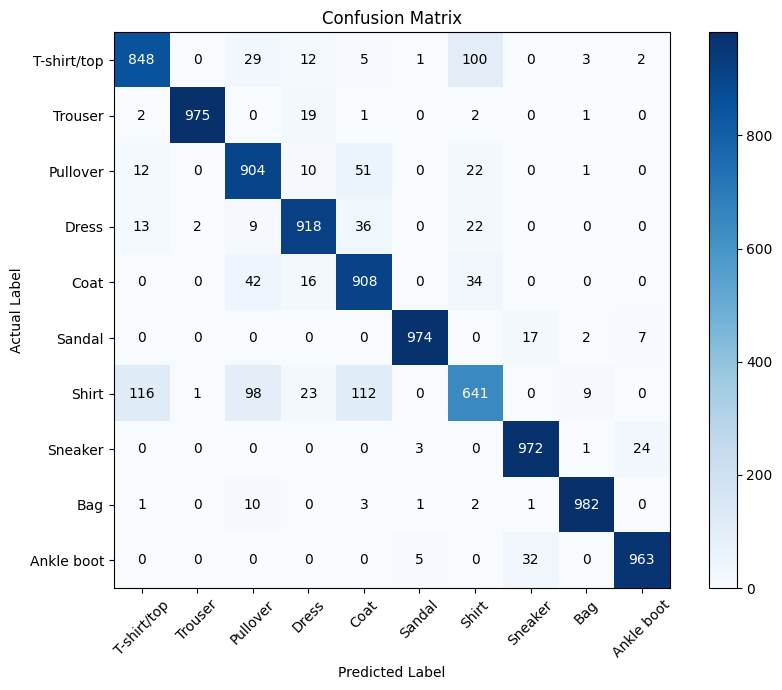

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

n_classes = len(class_names)

plt.xticks(range(n_classes), class_names, rotation=45)
plt.yticks(range(n_classes), class_names)

plt.colorbar()

for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.show()

In [ ]:
# Per-class accuracy (weakest classes first)
per_class = cm.diagonal() / cm.sum(axis=1)

for name, acc in sorted(zip(class_names, per_class), key=lambda t: t[1]):

    print(f"{name:15s}: {acc*100:.2f}%")

Shirt          : 64.10%
T-shirt/top    : 84.80%
Pullover       : 90.40%
Coat           : 90.80%
Dress          : 91.80%
Ankle boot     : 96.30%
Sneaker        : 97.20%
Sandal         : 97.40%
Trouser        : 97.50%
Bag            : 98.20%


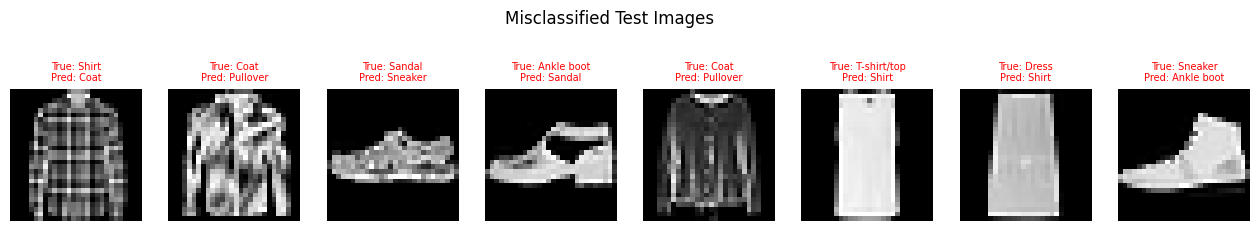

In [ ]:
# Show some wrongly classified test images
wrong = [i for i in range(len(all_labels)) if all_labels[i] != all_predictions[i]][:8]

fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for ax, i in zip(axes, wrong):

    img, _ = test_data[i]

    ax.imshow(img[0] * STD + MEAN, cmap='gray')
    ax.set_title(f"True: {class_names[all_labels[i]]}\nPred: {class_names[all_predictions[i]]}",
                 fontsize=7, color='red')
    ax.axis('off')

plt.suptitle('Misclassified Test Images')
plt.show()

## 17. Model Saving

The trained CNN model weights are saved
in a file named CNN_23-50691-1.pth.

This file can be used later to load
the trained model without training it again.
The file is only about 3.5 MB, so it can be uploaded to GitHub
(limit: 20 MB).

In [ ]:
torch.save(model.state_dict(), 'CNN_23-50691-1.pth')

print("Model Saved Successfully!")
print("File size: %.2f MB" % (os.path.getsize('CNN_23-50691-1.pth') / 1e6))

Model Saved Successfully!
File size: 3.59 MB


In [ ]:
# Load the saved weights into a fresh model and confirm the test accuracy is unchanged
loaded_model, _, _ = get_model()

loaded_model.load_state_dict(torch.load('CNN_23-50691-1.pth', map_location=device))

loaded_model.eval()

correct = 0

with torch.no_grad():

    for images, labels in test_dl:

        out = loaded_model(images.to(device))

        correct += (out.argmax(1).cpu() == labels).sum().item()

print("Reloaded Model Test Accuracy:", 100 * correct / len(test_data), "%")

Reloaded Model Test Accuracy: 90.85 %


# 18. Conclusion

In this assignment, a CNN model was developed
to classify clothing images into ten different categories
using the Fashion-MNIST dataset.

The model was trained with the Adam optimizer and cross-entropy loss,
and evaluated on the separate test set. The test accuracy,
the classification report and the confusion matrix are shown above.

The results show that even a small CNN with two convolutional layers
can classify clothing images well. The weakest classes are
usually **Shirt**, **T-shirt/top**, **Pullover** and **Coat**,
because these items look very similar at 28 x 28 resolution.
Footwear, bags and trousers are recognised most easily.

*(Write your final test accuracy here after running the notebook.)*

**Future work**

- Add Batch Normalization and more convolutional layers.
- Use stronger augmentation and a learning-rate scheduler.
- Train for more epochs with early stopping.
- Try transfer learning with a pre-trained network.

In [ ]:
# Final results summary
print("Final Training Accuracy  : %.2f%%" % (train_accuracies[-1] * 100))
print("Final Validation Accuracy: %.2f%%" % (val_accuracies[-1] * 100))
print("Test Accuracy            : %.2f%%" % test_accuracy)

Final Training Accuracy  : 91.67%
Final Validation Accuracy: 91.36%
Test Accuracy            : 90.85%


In [ ]:
# Download the model file (works in Google Colab only)
try:
    from google.colab import files
    files.download('CNN_23-50691-1.pth')
except ImportError:
    print("Not running in Colab - the model is saved in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>